In [20]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import surprise
from surprise import accuracy


In [21]:
dataset_path = Path('../dataset')
train_df = pd.read_csv(dataset_path / 'train.csv')
train_df.date = pd.to_datetime(train_df.date)

test_df = pd.read_csv(dataset_path / 'validation.csv')
test_df.date = pd.to_datetime(test_df.date)

train_df.head()

,user_id,recipe_id,date,rating
0,1293707,150898,2011-01-04,5
1,1293707,25360,2011-01-04,5
2,1293707,99564,2011-01-06,4
3,1293707,70758,2011-01-09,5
4,1293707,115110,2011-01-26,5


In [22]:
train_df.describe()

,user_id,recipe_id,date,rating
count,1.571080e+05,157108.000000,157108,157108.000000
mean,7.089527e+06,90281.169145,2007-07-23 01:53:33.758688,4.660094
min,1.533000e+03,62.000000,2001-04-18 00:00:00,0.000000
25%,9.757900e+04,32614.000000,2006-01-10 00:00:00,5.000000
50%,2.159560e+05,69484.000000,2007-09-01 00:00:00,5.000000
75%,4.379730e+05,119544.000000,2008-12-31 00:00:00,5.000000
max,2.001453e+09,496591.000000,2018-05-14 00:00:00,5.000000
std,1.130750e+08,76689.736519,NaN,0.833243


In [23]:
test_df

,user_id,recipe_id,date,rating
0,1293707,178556,2011-11-06,5
1,1293707,50144,2011-11-11,5
2,126440,107142,2013-05-15,4
3,126440,38339,2013-05-17,5
4,126440,71557,2013-05-18,5
...,...,...,...,...
27411,1079336,21138,2009-01-10,5
27412,1079336,39087,2009-01-10,5
27413,1079336,221217,2009-01-10,5
27414,18347,58516,2008-10-08,5


In [24]:
reader = surprise.reader.Reader(rating_scale=(0,5))

train_data = surprise.Dataset.load_from_df(
    train_df[["user_id", "recipe_id", "rating"]], reader=reader
)
trainset = train_data.build_full_trainset()

test_data = surprise.Dataset.load_from_df(
    test_df[["user_id", "recipe_id", "rating"]], reader=reader
)
testset = test_data.construct_testset(
    test_data.raw_ratings
)


In [25]:
k_values = [5, 10, 30, 50, 70, 100]
mae_values = []
rmse_values = []

for k in k_values:
  model = surprise.KNNBasic(k=k, sim_options={'name': 'pearson', 'user_based': True})
  model.fit(trainset)
  predictions = model.test(testset)
  rmse_values.append(accuracy.rmse(predictions))
  mae_values.append(accuracy.mae(predictions))

Computing the pearson similarity matrix...
Done computing similarity matrix.
RMSE: 1.0187
MAE:  0.5744
Computing the pearson similarity matrix...
Done computing similarity matrix.
RMSE: 1.0157
MAE:  0.5738
Computing the pearson similarity matrix...
Done computing similarity matrix.
RMSE: 1.0151
MAE:  0.5738
Computing the pearson similarity matrix...
Done computing similarity matrix.
RMSE: 1.0151
MAE:  0.5738
Computing the pearson similarity matrix...
Done computing similarity matrix.
RMSE: 1.0151
MAE:  0.5738
Computing the pearson similarity matrix...
Done computing similarity matrix.
RMSE: 1.0151
MAE:  0.5738


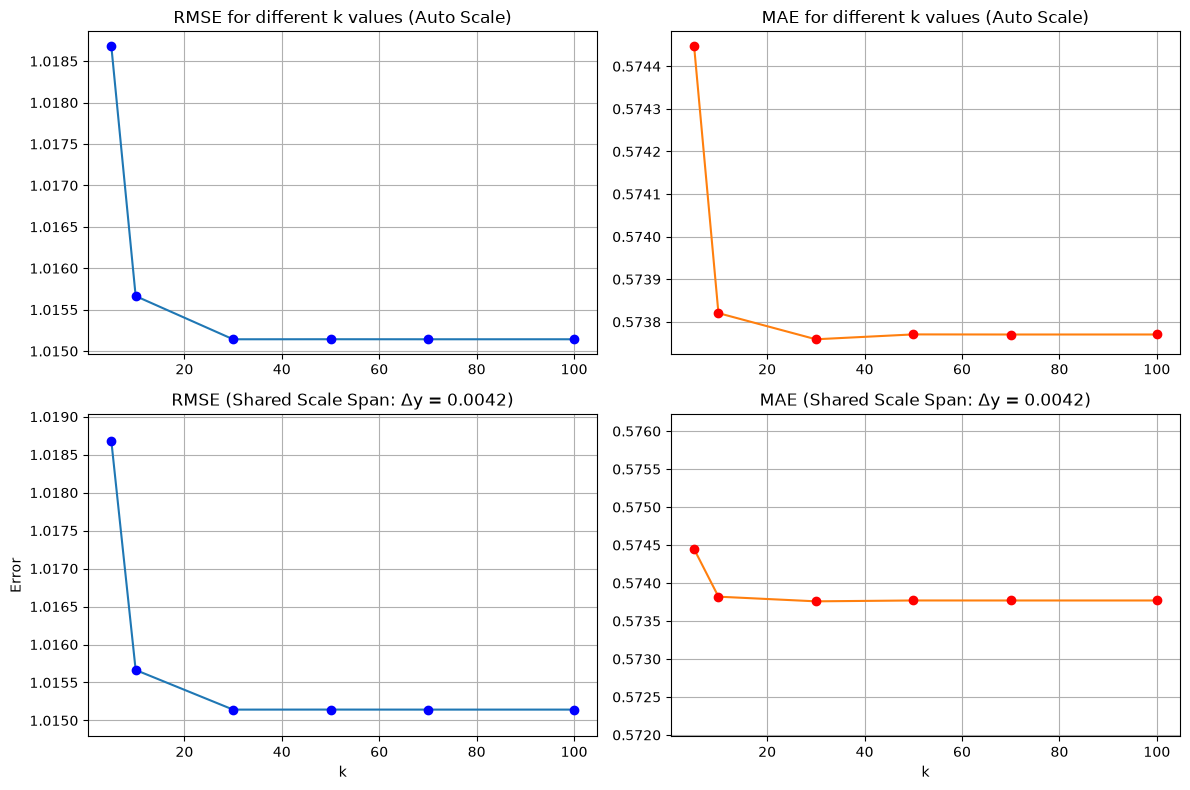

In [32]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))

# Top row: original auto scale
rmse_ax_top, mae_ax_top = axs[0, 0], axs[0, 1]

rmse_ax_top.plot(k_values, rmse_values, color="tab:blue")
rmse_ax_top.plot(k_values, rmse_values, "bo")
rmse_ax_top.grid(True)
rmse_ax_top.set_title("RMSE for different k values (Auto Scale)")

# Changed MAE top line and marker colors to orange / red
mae_ax_top.plot(k_values, mae_values, color="tab:orange")
mae_ax_top.plot(k_values, mae_values, "ro")
mae_ax_top.grid(True)
mae_ax_top.set_title("MAE for different k values (Auto Scale)")

# Bottom row: matching scale height and tick spacing
rmse_ax_bot, mae_ax_bot = axs[1, 0], axs[1, 1]

# 1. Determine common range span (delta) and tick interval
rmse_span = np.ptp(rmse_values)
mae_span = np.ptp(mae_values)
shared_span = max(rmse_span, mae_span) * 1.2  # Add 20% padding
tick_step = 0.0005  # Uniform tick line separation for both

# Center limits around each metric's midpoint
rmse_mid = (np.max(rmse_values) + np.min(rmse_values)) / 2
mae_mid = (np.max(mae_values) + np.min(mae_values)) / 2

rmse_ax_bot.set_ylim(rmse_mid - shared_span / 2, rmse_mid + shared_span / 2)
mae_ax_bot.set_ylim(mae_mid - shared_span / 2, mae_mid + shared_span / 2)

# Apply identical tick distance
rmse_ax_bot.yaxis.set_major_locator(ticker.MultipleLocator(tick_step))
mae_ax_bot.yaxis.set_major_locator(ticker.MultipleLocator(tick_step))

# 2. Plot bottom series
rmse_ax_bot.plot(k_values, rmse_values, color="tab:blue")
rmse_ax_bot.plot(k_values, rmse_values, "bo")
rmse_ax_bot.grid(True)
rmse_ax_bot.set_title(f"RMSE (Shared Scale Span: Δy = {shared_span:.4f})")
rmse_ax_bot.set_xlabel("k")
rmse_ax_bot.set_ylabel("Error")

mae_ax_bot.plot(k_values, mae_values, color="tab:orange")
mae_ax_bot.plot(k_values, mae_values, "ro")
mae_ax_bot.grid(True)
mae_ax_bot.set_title(f"MAE (Shared Scale Span: Δy = {shared_span:.4f})")
mae_ax_bot.set_xlabel("k")

plt.tight_layout()
plt.show()

## Best k for user knn = 30

In [30]:
from tarea_01.utils import calculate_metrics

best_k = 30

model = surprise.KNNBasic(k=best_k, sim_options={'name': 'pearson', 'user_based': True})
model.fit(trainset)

metrics = calculate_metrics(
    model=model,
    testset=testset,
    k=10,
    threshold=4.0,
)

metrics

Computing the pearson similarity matrix...
Done computing similarity matrix.


{'RMSE': 1.0151,
 'Recall@10': 0.9455,
 'Precision@10': 0.9396,
 'NDCG@10': 0.9725,
 'MAP@10': 0.9565,
 'Diversity': 0.8397,
 'Novelty': 11.9272}